In [41]:
from pathlib import Path
import torch

def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'HAM10000_metadata.csv').is_file() and (candidate / 'ISIC_ES' / 'ISIC2018_Task3_Training_Input').is_dir():
            return candidate
    raise FileNotFoundError('Open this notebook from the project folder or one of its subfolders.')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
METADATA_PATH = PROJECT_ROOT / 'HAM10000_metadata.csv'
IMAGE_DIR = PROJECT_ROOT / 'ISIC_ES' / 'ISIC2018_Task3_Training_Input'
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints'
CHECKPOINT_DIR.mkdir(exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Metadata:', METADATA_PATH)
print('Images:', IMAGE_DIR)


print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Project root: C:\Users\palva\ES_Project_vscode
Metadata: C:\Users\palva\ES_Project_vscode\HAM10000_metadata.csv
Images: C:\Users\palva\ES_Project_vscode\ISIC_ES\ISIC2018_Task3_Training_Input
GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [42]:
import os

for root, dirs, files in os.walk(PROJECT_ROOT):
    dirs[:] = [d for d in dirs if d not in ('.venv', '.git', '__pycache__', '.ipynb_checkpoints')]
    if files:
        print(root, ":", len(files), "files")


C:\Users\palva\ES_Project_vscode : 3 files
C:\Users\palva\ES_Project_vscode\checkpoints : 1 files
C:\Users\palva\ES_Project_vscode\ISIC_ES\ISIC2018_Task3_Training_Input : 10017 files
C:\Users\palva\ES_Project_vscode\Microsoft\Windows\PowerShell : 1 files


In [43]:
print('Using local project files; Google Drive is not required.')

Using local project files; Google Drive is not required.


In [44]:
import sys
print(sys.executable)

c:\Users\palva\ES_Project_vscode\.venv\Scripts\python.exe


In [45]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [46]:
import os

path = str(IMAGE_DIR)

print(os.path.exists(path))
print(os.listdir(path)[:10])

True
['ATTRIBUTION.txt', 'ISIC_0024306.jpg', 'ISIC_0024307.jpg', 'ISIC_0024308.jpg', 'ISIC_0024309.jpg', 'ISIC_0024310.jpg', 'ISIC_0024311.jpg', 'ISIC_0024312.jpg', 'ISIC_0024313.jpg', 'ISIC_0024314.jpg']


In [47]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [48]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.0 GB


In [49]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

x = torch.randn(1000, 1000).to(device)

print("Device:", x.device)

Device: cuda:0


In [50]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [51]:
import os

images = [
    f for f in os.listdir(path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of images:", len(images))

Number of images: 10015


In [52]:
import os

print("Current project folders:")
print(os.listdir(PROJECT_ROOT))

Current project folders:
['.venv', 'checkpoints', 'EMBEDDED__PROJECT.ipynb', 'ham10000_dataset.py', 'HAM10000_metadata.csv', 'ISIC_ES', 'Microsoft', '__pycache__']


In [53]:
import os

print('Local image directory exists:', IMAGE_DIR.exists())
print('Local metadata exists:', METADATA_PATH.exists())

Local image directory exists: True
Local metadata exists: True


In [54]:
import os

path = str(IMAGE_DIR)

csv_files = [
    f for f in os.listdir(path)
    if f.lower().endswith(".csv")
]

print("CSV files:")
print(csv_files)

CSV files:
[]


In [55]:
import os

path = str(IMAGE_DIR)

all_files = os.listdir(path)

print("Total files:", len(all_files))
print("\nFirst 20 files:")
for f in all_files[:20]:
    print(f)

Total files: 10017

First 20 files:
ATTRIBUTION.txt
ISIC_0024306.jpg
ISIC_0024307.jpg
ISIC_0024308.jpg
ISIC_0024309.jpg
ISIC_0024310.jpg
ISIC_0024311.jpg
ISIC_0024312.jpg
ISIC_0024313.jpg
ISIC_0024314.jpg
ISIC_0024315.jpg
ISIC_0024316.jpg
ISIC_0024317.jpg
ISIC_0024318.jpg
ISIC_0024319.jpg
ISIC_0024320.jpg
ISIC_0024321.jpg
ISIC_0024322.jpg
ISIC_0024323.jpg
ISIC_0024324.jpg


In [56]:
import os

# Search the local project for CSV files
for root, dirs, files in os.walk(PROJECT_ROOT):
    dirs[:] = [d for d in dirs if d not in ('.venv', '.git', '__pycache__', '.ipynb_checkpoints')]
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))


C:\Users\palva\ES_Project_vscode\HAM10000_metadata.csv


In [57]:
import pandas as pd

metadata = pd.read_csv(METADATA_PATH)

print(metadata.head())
print(metadata["dx"].value_counts())

     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [58]:
import os

images = [
    f for f in os.listdir(path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of images:", len(images))

Number of images: 10015


In [59]:
import os

path = str(IMAGE_DIR)

images = [
    f for f in os.listdir(path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of images:", len(images))

Number of images: 10015


In [60]:
import os

path = str(PROJECT_ROOT)

print("Metadata exists:",
      os.path.exists(os.path.join(path, "HAM10000_metadata.csv")))

Metadata exists: True


In [61]:
print('Using local project files; Google Drive is not required.')

Using local project files; Google Drive is not required.


In [62]:
import os

path = str(IMAGE_DIR)

print("Exists:", os.path.exists(path))
print("Files/folders inside:")
print(os.listdir(path)[:20])

Exists: True
Files/folders inside:
['ATTRIBUTION.txt', 'ISIC_0024306.jpg', 'ISIC_0024307.jpg', 'ISIC_0024308.jpg', 'ISIC_0024309.jpg', 'ISIC_0024310.jpg', 'ISIC_0024311.jpg', 'ISIC_0024312.jpg', 'ISIC_0024313.jpg', 'ISIC_0024314.jpg', 'ISIC_0024315.jpg', 'ISIC_0024316.jpg', 'ISIC_0024317.jpg', 'ISIC_0024318.jpg', 'ISIC_0024319.jpg', 'ISIC_0024320.jpg', 'ISIC_0024321.jpg', 'ISIC_0024322.jpg', 'ISIC_0024323.jpg', 'ISIC_0024324.jpg']


In [63]:
import os

path = str(IMAGE_DIR)

items = os.listdir(path)

print("Total items:", len(items))
print("\nFirst 20 items:")
for item in items[:20]:
    print(item)

Total items: 10017

First 20 items:
ATTRIBUTION.txt
ISIC_0024306.jpg
ISIC_0024307.jpg
ISIC_0024308.jpg
ISIC_0024309.jpg
ISIC_0024310.jpg
ISIC_0024311.jpg
ISIC_0024312.jpg
ISIC_0024313.jpg
ISIC_0024314.jpg
ISIC_0024315.jpg
ISIC_0024316.jpg
ISIC_0024317.jpg
ISIC_0024318.jpg
ISIC_0024319.jpg
ISIC_0024320.jpg
ISIC_0024321.jpg
ISIC_0024322.jpg
ISIC_0024323.jpg
ISIC_0024324.jpg


In [64]:
import os

path = str(IMAGE_DIR)

csv_files = [
    f for f in os.listdir(path)
    if f.lower().endswith(".csv")
]

print("CSV files found:")
for f in csv_files:
    print(f)

CSV files found:


In [65]:
import os

path = str(IMAGE_DIR)

non_images = [
    f for f in os.listdir(path)
    if not f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Non-image files:")
for f in non_images:
    print(f)

Non-image files:
ATTRIBUTION.txt
LICENSE.txt


In [66]:
import pandas as pd

path = METADATA_PATH

df = pd.read_csv(path)

print("Total metadata rows:", len(df))

print("\nClass distribution:")
print(df["dx"].value_counts())

Total metadata rows: 10015

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [67]:
import os
import pandas as pd

folder = IMAGE_DIR
metadata_path = METADATA_PATH

df = pd.read_csv(metadata_path)

# Get image IDs actually present in Drive
image_files = [
    f for f in os.listdir(folder)
    if f.lower().endswith(".jpg")
]

image_ids = [os.path.splitext(f)[0] for f in image_files]

# Match images with metadata
downloaded_df = df[df["image_id"].isin(image_ids)]

print("JPG images in Drive:", len(image_files))
print("Images matched to metadata:", len(downloaded_df))

print("\nClasses actually present in Drive:")
print(downloaded_df["dx"].value_counts())

JPG images in Drive: 10015
Images matched to metadata: 10015

Classes actually present in Drive:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [68]:
print("Columns in metadata:")
print(df.columns.tolist())

Columns in metadata:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [69]:
print("\nNumber of unique lesions:", df["lesion_id"].nunique())
print("Total images:", len(df))

print("\nImages per lesion:")
print(df["lesion_id"].value_counts().head(10))


Number of unique lesions: 7470
Total images: 10015

Images per lesion:
lesion_id
HAM_0003789    6
HAM_0000835    6
HAM_0001863    6
HAM_0005263    6
HAM_0000893    5
HAM_0007427    5
HAM_0007343    5
HAM_0007367    5
HAM_0002364    5
HAM_0003847    4
Name: count, dtype: int64


In [70]:
print(df.groupby("dx")["lesion_id"].nunique())

dx
akiec     228
bcc       327
bkl       727
df         73
mel       614
nv       5403
vasc       98
Name: lesion_id, dtype: int64


In [71]:
print(
    df.groupby("dx")["lesion_id"]
      .nunique()
)

dx
akiec     228
bcc       327
bkl       727
df         73
mel       614
nv       5403
vasc       98
Name: lesion_id, dtype: int64


In [72]:
from sklearn.model_selection import train_test_split

# Check that each lesion has only one diagnosis
lesion_labels = df.groupby("lesion_id")["dx"].nunique()

print("Lesions with multiple diagnoses:",
      (lesion_labels > 1).sum())

# Create one row per lesion
lesions = df[["lesion_id", "dx"]].drop_duplicates("lesion_id")

# 70% train, 30% temporary
train_lesions, temp_lesions = train_test_split(
    lesions,
    test_size=0.30,
    stratify=lesions["dx"],
    random_state=42
)

# Split remaining 30% equally → 15% validation, 15% test
val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["dx"],
    random_state=42
)

# Get the actual images belonging to each lesion group
train_df = df[df["lesion_id"].isin(train_lesions["lesion_id"])].copy()
val_df   = df[df["lesion_id"].isin(val_lesions["lesion_id"])].copy()
test_df  = df[df["lesion_id"].isin(test_lesions["lesion_id"])].copy()

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTrain class distribution:")
print(train_df["dx"].value_counts())

print("\nValidation class distribution:")
print(val_df["dx"].value_counts())

print("\nTest class distribution:")
print(test_df["dx"].value_counts())

Lesions with multiple diagnoses: 0
Train images: 7002
Validation images: 1532
Test images: 1481

Train class distribution:
dx
nv       4679
mel       778
bkl       774
bcc       366
akiec     230
vasc       99
df         76
Name: count, dtype: int64

Validation class distribution:
dx
nv       1034
mel       170
bkl       157
bcc        77
akiec      51
vasc       24
df         19
Name: count, dtype: int64

Test class distribution:
dx
nv       992
bkl      168
mel      165
bcc       71
akiec     46
df        20
vasc      19
Name: count, dtype: int64


In [73]:
# Classes we are using
classes = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

# Number of images we want for the main classes
TARGET = 200

# Random seed so everyone gets the same selection
SEED = 42

import pandas as pd

# Select up to 120 training images per class
train_small = pd.concat([
    group.sample(n=min(120, len(group)), random_state=SEED)
    for _, group in train_df.groupby("dx")
]).reset_index(drop=True)

# Select up to 30 validation images per class
val_small = pd.concat([
    group.sample(n=min(30, len(group)), random_state=SEED)
    for _, group in val_df.groupby("dx")
]).reset_index(drop=True)

# Select up to 50 test images per class
test_small = pd.concat([
    group.sample(n=min(50, len(group)), random_state=SEED)
    for _, group in test_df.groupby("dx")
]).reset_index(drop=True)

print("TRAIN:")
print(train_small["dx"].value_counts())

print("\nVALIDATION:")
print(val_small["dx"].value_counts())

print("\nTEST:")
print(test_small["dx"].value_counts())


TRAIN:
dx
akiec    120
bcc      120
bkl      120
mel      120
nv       120
vasc      99
df        76
Name: count, dtype: int64

VALIDATION:
dx
akiec    30
bcc      30
bkl      30
mel      30
nv       30
vasc     24
df       19
Name: count, dtype: int64

TEST:
dx
bcc      50
bkl      50
mel      50
nv       50
akiec    46
df       20
vasc     19
Name: count, dtype: int64


In [74]:
from PIL import Image
import os

folder = IMAGE_DIR

all_selected = pd.concat([
    train_small,
    val_small,
    test_small
])

bad_images = []

for image_id in all_selected["image_id"]:
    image_path = os.path.join(folder, image_id + ".jpg")

    if not os.path.exists(image_path):
        bad_images.append((image_id, "Missing"))
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception as e:
        bad_images.append((image_id, str(e)))

print("Selected images:", len(all_selected))
print("Bad/missing images:", len(bad_images))

if bad_images:
    print("\nProblem images:")
    print(bad_images[:20])
else:
    print("All selected images are valid.")

Selected images: 1253
Bad/missing images: 0
All selected images are valid.


In [75]:
# Local migration: selected images are read directly from IMAGE_DIR.
# No dataset copy is created or required.
source = IMAGE_DIR
destination = IMAGE_DIR

# Combine our selected datasets
selected = pd.concat([
    train_small,
    val_small,
    test_small
]).drop_duplicates("image_id")

print("Selected images:", len(selected))
print("Images available in local directory:", len(list(destination.glob('*.jpg'))))

Selected images: 1253
Images available in local directory: 10015


In [76]:
import os

destination = str(IMAGE_DIR)

images = [
    f for f in os.listdir(destination)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Images copied so far:", len(images))

Images copied so far: 10015


In [77]:
from PIL import Image
import os

folder = str(IMAGE_DIR)

bad_images = []

for filename in os.listdir(folder):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as e:
            bad_images.append((filename, str(e)))

print("Total images:", len(os.listdir(folder)))
print("Bad images:", len(bad_images))

if len(bad_images) == 0:
    print("✅ All selected images are valid.")
else:
    print("Problem images:")
    print(bad_images[:10])

Total images: 10017
Bad images: 0
✅ All selected images are valid.


In [78]:
import torch
import torchvision
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [79]:
import pandas as pd
# Balance the training dataframe to 120 samples per class
# by oversampling only the minority classes.

TARGET_TRAIN = 120
SEED = 42

balanced_train_parts = []

for cls in classes:
    class_data = train_small[train_small["dx"] == cls]

    if len(class_data) >= TARGET_TRAIN:
        # Already enough
        selected = class_data.sample(
            n=TARGET_TRAIN,
            random_state=SEED
        )
    else:
        # Oversample with replacement
        selected = class_data.sample(
            n=TARGET_TRAIN,
            replace=True,
            random_state=SEED
        )

    balanced_train_parts.append(selected)

balanced_train = pd.concat(
    balanced_train_parts,
    ignore_index=True
)

# Shuffle the final training dataframe
balanced_train = balanced_train.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("Balanced training distribution:")
print(balanced_train["dx"].value_counts())

print("\nTotal training samples:", len(balanced_train))

Balanced training distribution:
dx
vasc     120
df       120
nv       120
akiec    120
bkl      120
bcc      120
mel      120
Name: count, dtype: int64

Total training samples: 840


In [80]:
from torchvision import transforms

# Training images:
# We apply augmentation only to training data.
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test:
# NO random augmentation here.
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation ready.")
print("Validation/Test preprocessing ready.")

Training augmentation ready.
Validation/Test preprocessing ready.


In [81]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

# Convert class names to numbers
class_to_idx = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_id = row["image_id"]
        label_name = row["dx"]

        image_path = os.path.join(
            self.image_dir,
            image_id + ".jpg"
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[label_name]

        return image, label


# Create datasets
image_dir = str(IMAGE_DIR)

train_dataset = HAM10000Dataset(
    balanced_train,
    image_dir,
    train_transform
)

val_dataset = HAM10000Dataset(
    val_small,
    image_dir,
    val_test_transform
)

test_dataset = HAM10000Dataset(
    test_small,
    image_dir,
    val_test_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 840
Validation dataset: 193
Test dataset: 285


In [82]:
import pandas as pd
import os

image_dir = str(IMAGE_DIR)

all_selected = pd.concat([
    balanced_train,
    val_small,
    test_small
])

missing = []

for image_id in all_selected["image_id"].unique():
    image_path = os.path.join(image_dir, image_id + ".jpg")

    if not os.path.exists(image_path):
        missing.append(image_id)

print("Total required unique images:", all_selected["image_id"].nunique())
print("Images currently in local folder:",
      len([f for f in os.listdir(image_dir)
           if f.lower().endswith(".jpg")]))
print("Missing images:", len(missing))

if missing:
    print("\nFirst 20 missing:")
    print(missing[:20])
else:
    print("✅ No images are missing.")

Total required unique images: 1203
Images currently in local folder: 10015
Missing images: 0
✅ No images are missing.


In [83]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 27
Validation batches: 7
Test batches: 9


In [84]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels.tolist())
print("Image value range:", images.min().item(), "to", images.max().item())

Image batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: [0, 3, 2, 4, 2, 6, 5, 4, 3, 0, 6, 6, 6, 2, 3, 6, 5, 1, 4, 1, 3, 6, 6, 4, 0, 2, 1, 2, 3, 2, 4, 1]
Image value range: -2.1179039478302 to 2.5702831745147705


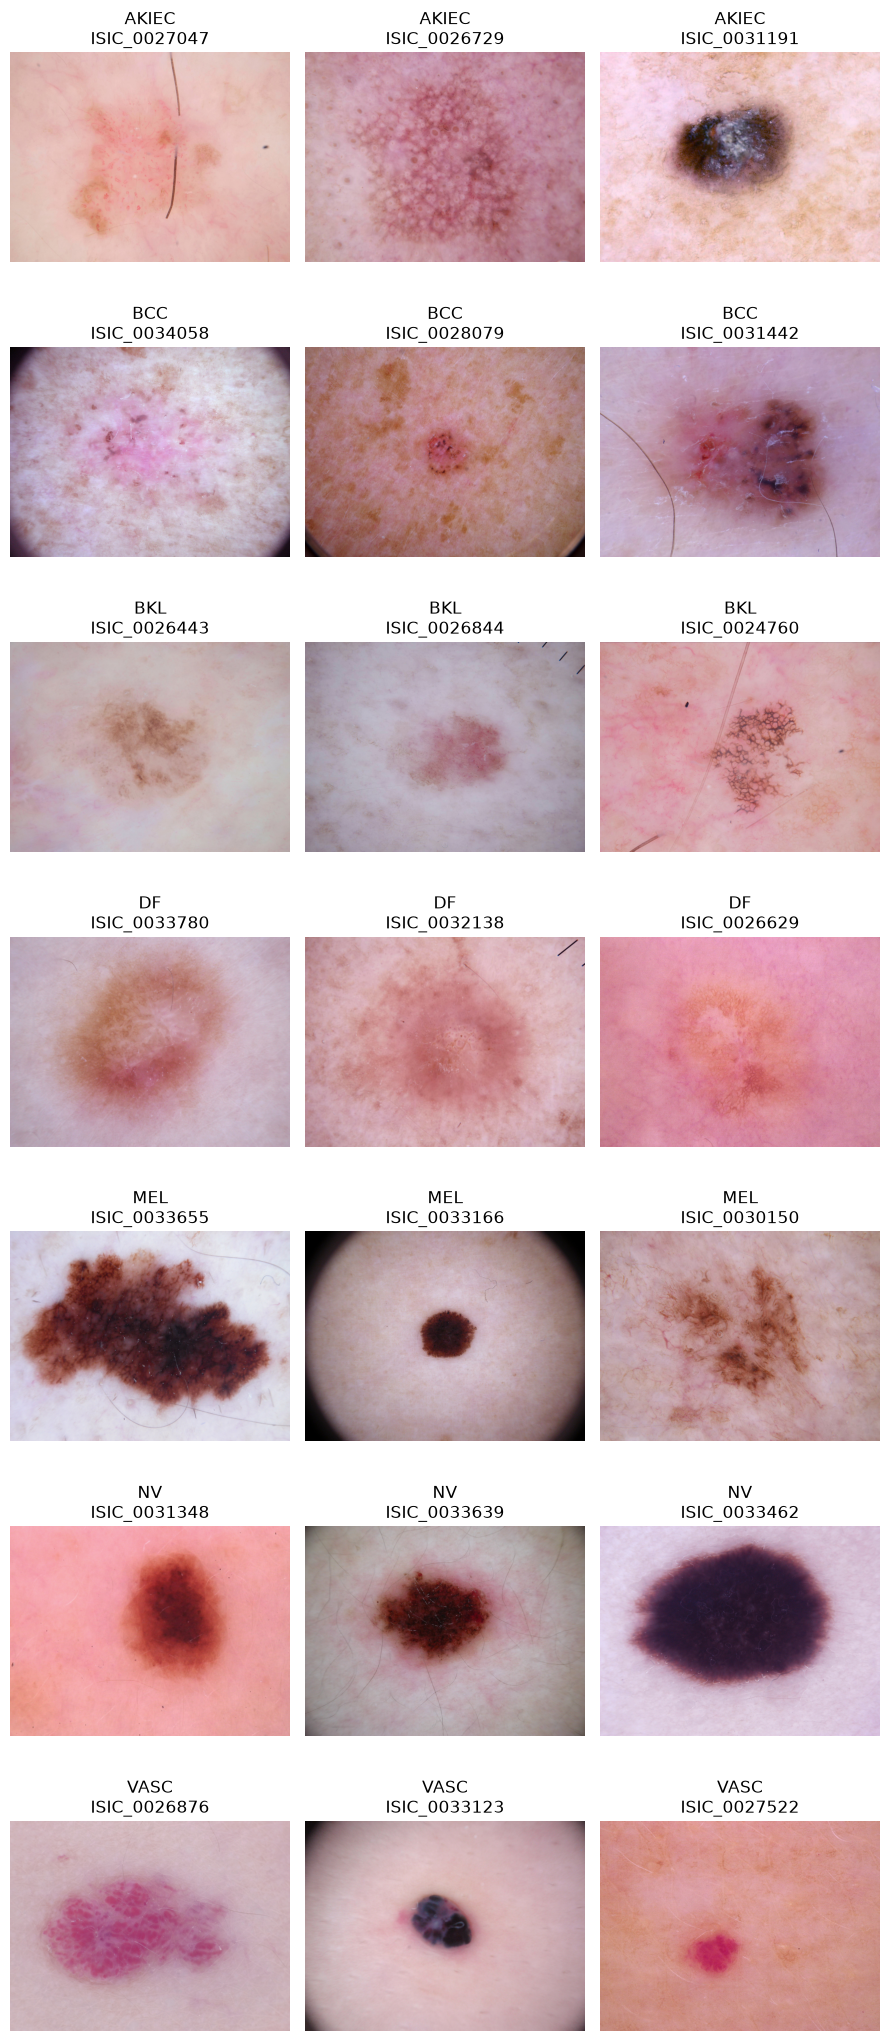

In [85]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

image_dir = str(IMAGE_DIR)

# Show 3 real images from each class
classes = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

fig, axes = plt.subplots(7, 3, figsize=(9, 21))

for row, cls in enumerate(classes):

    class_data = train_small[train_small["dx"] == cls]

    samples = class_data.sample(
        n=min(3, len(class_data)),
        random_state=42
    )

    for col, (_, item) in enumerate(samples.iterrows()):

        image_path = os.path.join(
            image_dir,
            item["image_id"] + ".jpg"
        )

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"{cls.upper()}\n{item['image_id']}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

ResNet50

In [86]:
print("TRAIN:")
print(balanced_train["dx"].value_counts().sort_index())

print("\nVALIDATION:")
print(val_small["dx"].value_counts().sort_index())

print("\nTEST:")
print(test_small["dx"].value_counts().sort_index())

TRAIN:
dx
akiec    120
bcc      120
bkl      120
df       120
mel      120
nv       120
vasc     120
Name: count, dtype: int64

VALIDATION:
dx
akiec    30
bcc      30
bkl      30
df       19
mel      30
nv       30
vasc     24
Name: count, dtype: int64

TEST:
dx
akiec    46
bcc      50
bkl      50
df       20
mel      50
nv       50
vasc     19
Name: count, dtype: int64


In [87]:
import torch
from torchvision import models
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ImageNet-pretrained ResNet50
model = models.resnet50(weights="IMAGENET1K_V2")

# Replace the final layer: 1000 ImageNet classes → 7 skin classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 7)

model = model.to(device)

print("Device:", device)
print("Model: ResNet50")
print("Output classes:", model.fc.out_features)

Device: cuda
Model: ResNet50
Output classes: 7


In [88]:
import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Number of epochs
NUM_EPOCHS = 10

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", NUM_EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Epochs: 10


In [89]:
from tqdm import tqdm
import torch

best_val_acc = 0.0

train_history = []
val_history = []

for epoch in range(NUM_EPOCHS):

    # -------------------------
    # TRAIN
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} - Training"
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_history.append((train_loss, train_acc))
    val_history.append((val_loss, val_acc))

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS}"
        f"\nTrain Loss: {train_loss:.4f}"
        f" | Train Accuracy: {train_acc:.4f}"
        f"\nVal Loss: {val_loss:.4f}"
        f" | Val Accuracy: {val_acc:.4f}"
    )

    # Save best model
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / 'best_resnet50_ham10000.pth'
        )

        print("✅ Best model saved!")

print("\nTraining finished.")
print("Best validation accuracy:", best_val_acc)

Epoch 1/10 - Training: 100%|██████████| 27/27 [00:28<00:00,  1.06s/it]



Epoch 1/10
Train Loss: 1.8111 | Train Accuracy: 0.3607
Val Loss: 1.6050 | Val Accuracy: 0.4974
✅ Best model saved!


Epoch 2/10 - Training: 100%|██████████| 27/27 [00:14<00:00,  1.85it/s]



Epoch 2/10
Train Loss: 1.2541 | Train Accuracy: 0.6452
Val Loss: 1.1487 | Val Accuracy: 0.6114
✅ Best model saved!


Epoch 3/10 - Training: 100%|██████████| 27/27 [00:14<00:00,  1.91it/s]


...


Epoch 6/10
Train Loss: 0.3096 | Train Accuracy: 0.8940
Val Loss: 0.9972 | Val Accuracy: 0.7098
✅ Best model saved!


Epoch 7/10 - Training: 100%|██████████| 27/27 [00:50<00:00,  1.86s/it]



Epoch 7/10
Train Loss: 0.2820 | Train Accuracy: 0.9024
Val Loss: 0.9755 | Val Accuracy: 0.7202
✅ Best model saved!


Epoch 8/10 - Training:  19%|█▊        | 5/27 [00:11<00:51,  2.34s/it]


KeyboardInterrupt: 

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import torch

# Load the BEST validation model
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_resnet50_ham10000.pth',
        map_location=device
    )
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

# Metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("TEST RESULTS")
print("=" * 40)
print(f"Accuracy:         {accuracy:.4f}")
print(f"Macro Precision:   {precision:.4f}")
print(f"Macro Recall:      {recall:.4f}")
print(f"Macro F1:          {f1:.4f}")

print("\nDetailed classification report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "AKIEC",
            "BCC",
            "BKL",
            "DF",
            "MEL",
            "NV",
            "VASC"
        ],
        zero_division=0
    )
)

TEST RESULTS
Accuracy:         0.6667
Macro Precision:   0.6979
Macro Recall:      0.6860
Macro F1:          0.6844

Detailed classification report:
              precision    recall  f1-score   support

       AKIEC       0.58      0.65      0.61        46
         BCC       0.69      0.70      0.69        50
         BKL       0.65      0.44      0.52        50
          DF       0.79      0.55      0.65        20
         MEL       0.60      0.62      0.61        50
          NV       0.69      0.84      0.76        50
        VASC       0.90      1.00      0.95        19

    accuracy                           0.67       285
   macro avg       0.70      0.69      0.68       285
weighted avg       0.67      0.67      0.66       285



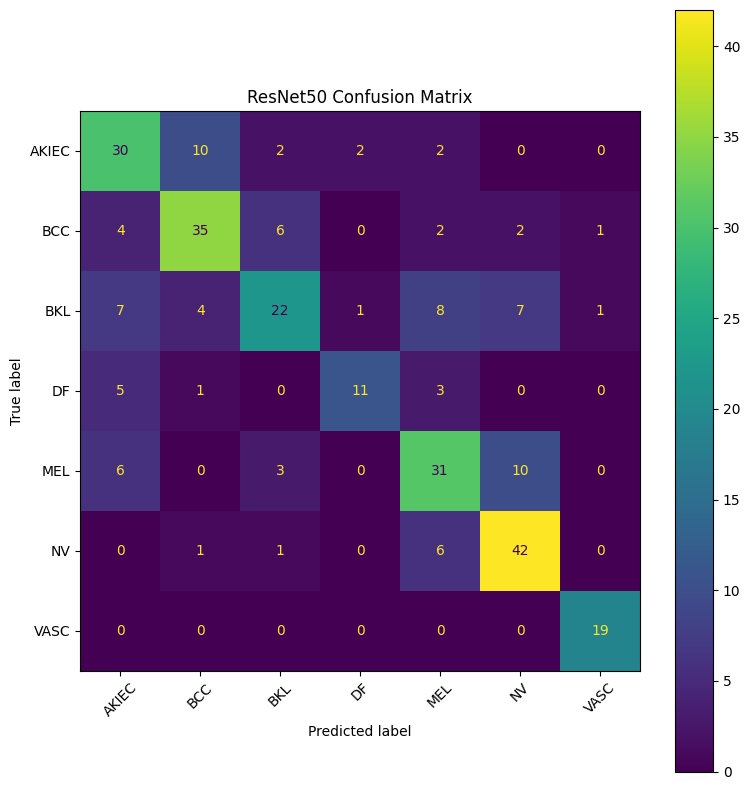

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

cm = confusion_matrix(
    all_labels,
    all_predictions
)

fig, ax = plt.subplots(figsize=(8, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, xticks_rotation=45)
plt.title("ResNet50 Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
import numpy as np

# Balanced Accuracy
balanced_acc = balanced_accuracy_score(
    all_labels,
    all_predictions
)

print("Balanced Accuracy:", round(balanced_acc, 4))
print("Balanced Accuracy (%):", round(balanced_acc * 100, 2))

# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

# Calculate specificity for each class
specificities = {}

for i, class_name in enumerate(class_names):
    true_negative = cm.sum() - (
        cm[i, :].sum() +
        cm[:, i].sum() -
        cm[i, i]
    )

    false_positive = cm[:, i].sum() - cm[i, i]

    specificity = true_negative / (
        true_negative + false_positive
    )

    specificities[class_name] = specificity

print("\nSpecificity by class:")
for cls, value in specificities.items():
    print(f"{cls}: {value:.4f} ({value*100:.2f}%)")

Balanced Accuracy: 0.686
Balanced Accuracy (%): 68.6

Specificity by class:
AKIEC: 0.9079 (90.79%)
BCC: 0.9319 (93.19%)
BKL: 0.9489 (94.89%)
DF: 0.9887 (98.87%)
MEL: 0.9106 (91.06%)
NV: 0.9191 (91.91%)
VASC: 0.9925 (99.25%)


In [ ]:
from sklearn.metrics import roc_auc_score
import torch
import numpy as np

# Make sure we're using the best model
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_resnet50_ham10000.pth',
        map_location=device
    )
)

model.eval()

all_probs = []
all_labels_auc = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        # Convert logits to probabilities
        probs = torch.softmax(outputs, dim=1)

        all_probs.extend(probs.cpu().numpy())
        all_labels_auc.extend(labels.numpy())

all_probs = np.array(all_probs)
all_labels_auc = np.array(all_labels_auc)

# One-hot encode the true labels
num_classes = 7
y_true_onehot = np.eye(num_classes)[all_labels_auc]

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

# AUROC for each class
print("AUROC by class:")
print("=" * 40)

auc_values = []

for i, class_name in enumerate(class_names):

    auc = roc_auc_score(
        y_true_onehot[:, i],
        all_probs[:, i]
    )

    auc_values.append(auc)

    print(f"{class_name}: {auc:.4f}")

# Macro AUROC
macro_auc = np.mean(auc_values)

print("\nMacro AUROC:", round(macro_auc, 4))
print("Macro AUROC (%):", round(macro_auc * 100, 2))

AUROC by class:
AKIEC: 0.9160
BCC: 0.9338
BKL: 0.8599
DF: 0.9570
MEL: 0.8892
NV: 0.9487
VASC: 0.9984

Macro AUROC: 0.929
Macro AUROC (%): 92.9


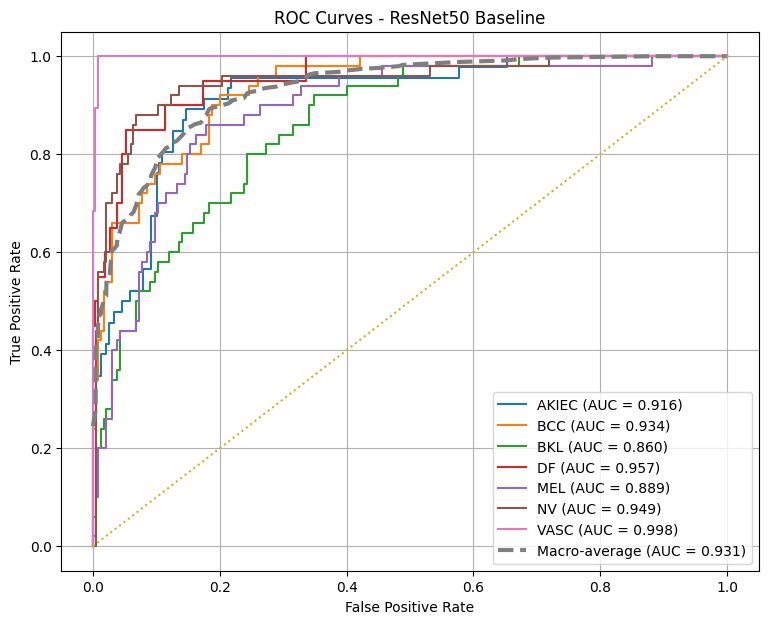

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "AKIEC", "BCC", "BKL", "DF",
    "MEL", "NV", "VASC"
]

plt.figure(figsize=(9, 7))

# Store all ROC curves
fpr_all = []
tpr_all = []

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_onehot[:, i],
        all_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    fpr_all.append(fpr)
    tpr_all.append(tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Macro-average ROC curve
all_fpr = np.unique(
    np.concatenate(fpr_all)
)

mean_tpr = np.zeros_like(all_fpr)

for fpr, tpr in zip(fpr_all, tpr_all):
    mean_tpr += np.interp(all_fpr, fpr, tpr)

mean_tpr /= len(class_names)

macro_auc_curve = auc(all_fpr, mean_tpr)

plt.plot(
    all_fpr,
    mean_tpr,
    linestyle="--",
    linewidth=3,
    label=f"Macro-average (AUC = {macro_auc_curve:.3f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - ResNet50 Baseline")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

DenseNet121

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

np.random.seed(42)

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

n_bootstrap = 2000
n = len(y_true)

accuracy_scores = []
balanced_acc_scores = []
macro_f1_scores = []

for _ in range(n_bootstrap):

    # Randomly sample test cases with replacement
    indices = np.random.randint(0, n, n)

    true_sample = y_true[indices]
    pred_sample = y_pred[indices]

    accuracy_scores.append(
        accuracy_score(true_sample, pred_sample)
    )

    balanced_acc_scores.append(
        balanced_accuracy_score(true_sample, pred_sample)
    )

    macro_f1_scores.append(
        f1_score(
            true_sample,
            pred_sample,
            average="macro",
            zero_division=0
        )
    )


def get_ci(scores):
    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)
    return lower, upper


acc_ci = get_ci(accuracy_scores)
bal_ci = get_ci(balanced_acc_scores)
f1_ci = get_ci(macro_f1_scores)


print("95% Confidence Intervals")
print("=" * 45)

print(
    f"Accuracy: {accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {acc_ci[0]:.4f} - {acc_ci[1]:.4f})"
)

print(
    f"Balanced Accuracy: {balanced_accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {bal_ci[0]:.4f} - {bal_ci[1]:.4f})"
)

print(
    f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f} "
    f"(95% CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f})"
)

95% Confidence Intervals
Accuracy: 0.6667 (95% CI: 0.6105 - 0.7193)
Balanced Accuracy: 0.6860 (95% CI: 0.6323 - 0.7387)
Macro F1: 0.6844 (95% CI: 0.6265 - 0.7346)


In [ ]:
from torchvision import models
import torch.nn as nn

# Load ImageNet-pretrained DenseNet121
densenet = models.densenet121(weights="IMAGENET1K_V1")

# Replace final classifier: 1000 ImageNet classes → 7 skin-lesion classes
num_features = densenet.classifier.in_features
densenet.classifier = nn.Linear(num_features, 7)

# Move to GPU
densenet = densenet.to(device)

print("Device:", device)
print("Model: DenseNet121")
print("Output classes:", densenet.classifier.out_features)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 41.5MB/s]


Device: cuda
Model: DenseNet121
Output classes: 7


In [ ]:
criterion_dense = nn.CrossEntropyLoss()

optimizer_dense = torch.optim.Adam(
    densenet.parameters(),
    lr=0.0001
)

NUM_EPOCHS_DENSE = 10

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Epochs:", NUM_EPOCHS_DENSE)

Loss: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.0001
Epochs: 10


In [ ]:
from tqdm import tqdm
import torch

best_val_acc_dense = 0.0

train_history_dense = []
val_history_dense = []

for epoch in range(NUM_EPOCHS_DENSE):

    # =========================
    # TRAIN
    # =========================
    densenet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS_DENSE} - DenseNet121"
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_dense.zero_grad()

        outputs = densenet(images)
        loss = criterion_dense(outputs, labels)

        loss.backward()
        optimizer_dense.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # =========================
    # VALIDATION
    # =========================
    densenet.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet(images)
            loss = criterion_dense(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_history_dense.append((train_loss, train_acc))
    val_history_dense.append((val_loss, val_acc))

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS_DENSE}"
        f"\nTrain Loss: {train_loss:.4f}"
        f" | Train Accuracy: {train_acc:.4f}"
        f"\nVal Loss: {val_loss:.4f}"
        f" | Val Accuracy: {val_acc:.4f}"
    )

    # Save best DenseNet model
    if val_acc > best_val_acc_dense:

        best_val_acc_dense = val_acc

        torch.save(
            densenet.state_dict(),
            CHECKPOINT_DIR / 'best_densenet121_ham10000.pth'
        )

        print("✅ Best DenseNet121 model saved!")

print("\nDenseNet121 training finished.")
print(
    "Best validation accuracy:",
    best_val_acc_dense
)

Epoch 1/10 - DenseNet121: 100%|██████████| 27/27 [00:17<00:00,  1.56it/s]



Epoch 1/10
Train Loss: 1.5593 | Train Accuracy: 0.4345
Val Loss: 1.2776 | Val Accuracy: 0.6010
✅ Best DenseNet121 model saved!


Epoch 2/10 - DenseNet121: 100%|██████████| 27/27 [00:11<00:00,  2.37it/s]



Epoch 2/10
Train Loss: 0.9468 | Train Accuracy: 0.7048
Val Loss: 1.0406 | Val Accuracy: 0.6373
✅ Best DenseNet121 model saved!


Epoch 3/10 - DenseNet121: 100%|██████████| 27/27 [00:12<00:00,  2.09it/s]


...


Epoch 8/10
Train Loss: 0.2675 | Train Accuracy: 0.9202
Val Loss: 0.8782 | Val Accuracy: 0.6943


Epoch 9/10 - DenseNet121: 100%|██████████| 27/27 [00:09<00:00,  2.88it/s]



Epoch 9/10
Train Loss: 0.2359 | Train Accuracy: 0.9393
Val Loss: 0.9358 | Val Accuracy: 0.6684


Epoch 10/10 - DenseNet121: 100%|██████████| 27/27 [00:10<00:00,  2.62it/s]



Epoch 10/10
Train Loss: 0.1661 | Train Accuracy: 0.9583
Val Loss: 0.9350 | Val Accuracy: 0.6684

DenseNet121 training finished.
Best validation accuracy: 0.694300518134715


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import torch

# Load best DenseNet121 model
densenet.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_densenet121_ham10000.pth',
        map_location=device
    )
)

densenet.eval()

all_predictions_dense = []
all_labels_dense = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = densenet(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_dense.extend(
            predictions.cpu().numpy()
        )

        all_labels_dense.extend(
            labels.numpy()
        )

# Calculate metrics
accuracy_dense = accuracy_score(
    all_labels_dense,
    all_predictions_dense
)

precision_dense = precision_score(
    all_labels_dense,
    all_predictions_dense,
    average="macro",
    zero_division=0
)

recall_dense = recall_score(
    all_labels_dense,
    all_predictions_dense,
    average="macro",
    zero_division=0
)

f1_dense = f1_score(
    all_labels_dense,
    all_predictions_dense,
    average="macro",
    zero_division=0
)

print("DENSENET121 TEST RESULTS")
print("=" * 45)
print(f"Accuracy:        {accuracy_dense:.4f}")
print(f"Macro Precision:  {precision_dense:.4f}")
print(f"Macro Recall:     {recall_dense:.4f}")
print(f"Macro F1:         {f1_dense:.4f}")

print("\nDetailed classification report:")
print(
    classification_report(
        all_labels_dense,
        all_predictions_dense,
        target_names=[
            "AKIEC",
            "BCC",
            "BKL",
            "DF",
            "MEL",
            "NV",
            "VASC"
        ],
        zero_division=0
    )
)

DENSENET121 TEST RESULTS
Accuracy:        0.6491
Macro Precision:  0.6803
Macro Recall:     0.6758
Macro F1:         0.6770

Detailed classification report:
              precision    recall  f1-score   support

       AKIEC       0.58      0.63      0.60        46
         BCC       0.63      0.58      0.60        50
         BKL       0.51      0.56      0.53        50
          DF       0.67      0.60      0.63        20
         MEL       0.60      0.60      0.60        50
          NV       0.83      0.76      0.79        50
        VASC       0.95      1.00      0.97        19

    accuracy                           0.65       285
   macro avg       0.68      0.68      0.68       285
weighted avg       0.65      0.65      0.65       285



EfficientNet-B0

In [ ]:
from torchvision import models
import torch.nn as nn

# Load ImageNet-pretrained EfficientNet-B0
efficientnet = models.efficientnet_b0(
    weights="IMAGENET1K_V1"
)

# Replace final classifier: 1000 → 7 classes
num_features = efficientnet.classifier[1].in_features

efficientnet.classifier[1] = nn.Linear(
    num_features,
    7
)

# Move to GPU
efficientnet = efficientnet.to(device)

print("Device:", device)
print("Model: EfficientNet-B0")
print("Output classes:", efficientnet.classifier[1].out_features)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 86.9MB/s]


Device: cuda
Model: EfficientNet-B0
Output classes: 7


In [ ]:
criterion_eff = nn.CrossEntropyLoss()

optimizer_eff = torch.optim.Adam(
    efficientnet.parameters(),
    lr=0.0001
)

NUM_EPOCHS_EFF = 10

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Epochs:", NUM_EPOCHS_EFF)

Loss: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.0001
Epochs: 10


In [ ]:
from tqdm import tqdm
import torch

best_val_acc_eff = 0.0

train_history_eff = []
val_history_eff = []

for epoch in range(NUM_EPOCHS_EFF):

    # =========================
    # TRAIN
    # =========================
    efficientnet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS_EFF} - EfficientNet-B0"
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_eff.zero_grad()

        outputs = efficientnet(images)
        loss = criterion_eff(outputs, labels)

        loss.backward()
        optimizer_eff.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # =========================
    # VALIDATION
    # =========================
    efficientnet.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet(images)
            loss = criterion_eff(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_history_eff.append((train_loss, train_acc))
    val_history_eff.append((val_loss, val_acc))

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS_EFF}"
        f"\nTrain Loss: {train_loss:.4f}"
        f" | Train Accuracy: {train_acc:.4f}"
        f"\nVal Loss: {val_loss:.4f}"
        f" | Val Accuracy: {val_acc:.4f}"
    )

    # Save best model
    if val_acc > best_val_acc_eff:

        best_val_acc_eff = val_acc

        torch.save(
            efficientnet.state_dict(),
            CHECKPOINT_DIR / 'best_efficientnet_b0_ham10000.pth'
        )

        print("✅ Best EfficientNet-B0 model saved!")

print("\nEfficientNet-B0 training finished.")
print("Best validation accuracy:", best_val_acc_eff)

Epoch 1/10 - EfficientNet-B0: 100%|██████████| 27/27 [00:13<00:00,  2.06it/s]



Epoch 1/10
Train Loss: 1.8257 | Train Accuracy: 0.3000
Val Loss: 1.6968 | Val Accuracy: 0.4093
✅ Best EfficientNet-B0 model saved!


Epoch 2/10 - EfficientNet-B0: 100%|██████████| 27/27 [00:07<00:00,  3.52it/s]



Epoch 2/10
Train Loss: 1.4425 | Train Accuracy: 0.5964
Val Loss: 1.4177 | Val Accuracy: 0.5544
✅ Best EfficientNet-B0 model saved!


Epoch 3/10 - EfficientNet-B0: 100%|██████████| 27/27 [00:11<00:00,  2.29it/s]


...


Epoch 8/10
Train Loss: 0.4549 | Train Accuracy: 0.8393
Val Loss: 0.8610 | Val Accuracy: 0.6788


Epoch 9/10 - EfficientNet-B0: 100%|██████████| 27/27 [00:11<00:00,  2.28it/s]



Epoch 9/10
Train Loss: 0.3541 | Train Accuracy: 0.8845
Val Loss: 0.8482 | Val Accuracy: 0.7047
✅ Best EfficientNet-B0 model saved!


Epoch 10/10 - EfficientNet-B0: 100%|██████████| 27/27 [00:08<00:00,  3.30it/s]



Epoch 10/10
Train Loss: 0.2919 | Train Accuracy: 0.9012
Val Loss: 0.8464 | Val Accuracy: 0.6995

EfficientNet-B0 training finished.
Best validation accuracy: 0.7046632124352331


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np
import torch

# Load the best EfficientNet-B0 checkpoint
efficientnet.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_efficientnet_b0_ham10000.pth',
        map_location=device
    )
)

efficientnet.eval()

all_predictions_eff = []
all_labels_eff = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = efficientnet(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_eff.extend(
            predictions.cpu().numpy()
        )

        all_labels_eff.extend(
            labels.numpy()
        )

# Main metrics
accuracy_eff = accuracy_score(
    all_labels_eff,
    all_predictions_eff
)

precision_eff = precision_score(
    all_labels_eff,
    all_predictions_eff,
    average="macro",
    zero_division=0
)

recall_eff = recall_score(
    all_labels_eff,
    all_predictions_eff,
    average="macro",
    zero_division=0
)

f1_eff = f1_score(
    all_labels_eff,
    all_predictions_eff,
    average="macro",
    zero_division=0
)

print("EFFICIENTNET-B0 TEST RESULTS")
print("=" * 45)

print(f"Accuracy:        {accuracy_eff:.4f}")
print(f"Macro Precision:  {precision_eff:.4f}")
print(f"Macro Recall:     {recall_eff:.4f}")
print(f"Macro F1:         {f1_eff:.4f}")

print("\nDetailed classification report:")

print(
    classification_report(
        all_labels_eff,
        all_predictions_eff,
        target_names=[
            "AKIEC",
            "BCC",
            "BKL",
            "DF",
            "MEL",
            "NV",
            "VASC"
        ],
        zero_division=0
    )
)

EFFICIENTNET-B0 TEST RESULTS
Accuracy:        0.6561
Macro Precision:  0.6805
Macro Recall:     0.6652
Macro F1:         0.6687

Detailed classification report:
              precision    recall  f1-score   support

       AKIEC       0.64      0.80      0.71        46
         BCC       0.69      0.68      0.69        50
         BKL       0.53      0.62      0.57        50
          DF       0.61      0.55      0.58        20
         MEL       0.59      0.44      0.51        50
          NV       0.75      0.72      0.73        50
        VASC       0.94      0.84      0.89        19

    accuracy                           0.66       285
   macro avg       0.68      0.67      0.67       285
weighted avg       0.66      0.66      0.65       285



In [ ]:
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
import numpy as np

y_true_eff = np.array(all_labels_eff)
y_pred_eff = np.array(all_predictions_eff)

# Balanced Accuracy
balanced_acc_eff = balanced_accuracy_score(
    y_true_eff,
    y_pred_eff
)

print("Balanced Accuracy:",
      round(balanced_acc_eff, 4))

print("Balanced Accuracy (%):",
      round(balanced_acc_eff * 100, 2))


# Confusion matrix
cm_eff = confusion_matrix(
    y_true_eff,
    y_pred_eff
)

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

# Specificity for each class
print("\nSpecificity by class:")
print("=" * 40)

for i, class_name in enumerate(class_names):

    true_negative = cm_eff.sum() - (
        cm_eff[i, :].sum()
        + cm_eff[:, i].sum()
        - cm_eff[i, i]
    )

    false_positive = (
        cm_eff[:, i].sum() - cm_eff[i, i]
    )

    specificity = true_negative / (
        true_negative + false_positive
    )

    print(
        f"{class_name}: "
        f"{specificity:.4f} "
        f"({specificity * 100:.2f}%)"
    )

Balanced Accuracy: 0.6652
Balanced Accuracy (%): 66.52

Specificity by class:
AKIEC: 0.9121 (91.21%)
BCC: 0.9362 (93.62%)
BKL: 0.8851 (88.51%)
DF: 0.9736 (97.36%)
MEL: 0.9362 (93.62%)
NV: 0.9489 (94.89%)
VASC: 0.9962 (99.62%)


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np

# Get probability scores from EfficientNet
efficientnet.eval()

all_probs_eff = []
all_labels_auc_eff = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = efficientnet(images)

        probs = torch.softmax(outputs, dim=1)

        all_probs_eff.extend(
            probs.cpu().numpy()
        )

        all_labels_auc_eff.extend(
            labels.numpy()
        )

all_probs_eff = np.array(all_probs_eff)
all_labels_auc_eff = np.array(all_labels_auc_eff)

# One-hot labels
num_classes = 7
y_true_onehot_eff = np.eye(num_classes)[all_labels_auc_eff]

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

print("EfficientNet-B0 AUROC by class:")
print("=" * 45)

auc_values_eff = []

for i, class_name in enumerate(class_names):

    auc = roc_auc_score(
        y_true_onehot_eff[:, i],
        all_probs_eff[:, i]
    )

    auc_values_eff.append(auc)

    print(f"{class_name}: {auc:.4f}")

macro_auc_eff = np.mean(auc_values_eff)

print("\nMacro AUROC:", round(macro_auc_eff, 4))
print("Macro AUROC (%):", round(macro_auc_eff * 100, 2))

EfficientNet-B0 AUROC by class:
AKIEC: 0.9166
BCC: 0.9458
BKL: 0.8560
DF: 0.9657
MEL: 0.8264
NV: 0.9587
VASC: 0.9982

Macro AUROC: 0.9239
Macro AUROC (%): 92.39


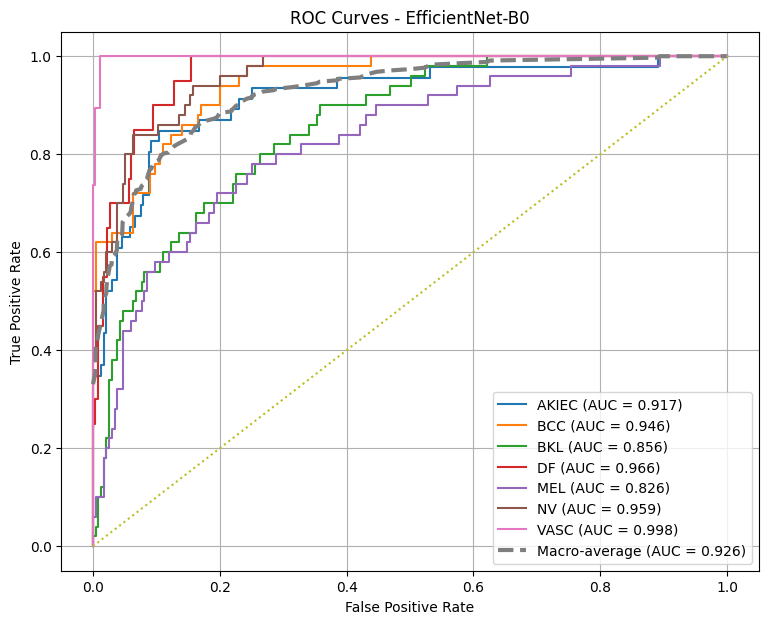

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

fpr_all_eff = []
tpr_all_eff = []

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_onehot_eff[:, i],
        all_probs_eff[:, i]
    )

    roc_auc = auc(fpr, tpr)

    fpr_all_eff.append(fpr)
    tpr_all_eff.append(tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Macro-average ROC
all_fpr_eff = np.unique(
    np.concatenate(fpr_all_eff)
)

mean_tpr_eff = np.zeros_like(all_fpr_eff)

for fpr, tpr in zip(fpr_all_eff, tpr_all_eff):
    mean_tpr_eff += np.interp(
        all_fpr_eff,
        fpr,
        tpr
    )

mean_tpr_eff /= len(class_names)

macro_auc_curve_eff = auc(
    all_fpr_eff,
    mean_tpr_eff
)

plt.plot(
    all_fpr_eff,
    mean_tpr_eff,
    linestyle="--",
    linewidth=3,
    label=f"Macro-average (AUC = {macro_auc_curve_eff:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - EfficientNet-B0")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

np.random.seed(42)

y_true = np.array(all_labels_eff)
y_pred = np.array(all_predictions_eff)

n_bootstrap = 2000
n = len(y_true)

accuracy_scores = []
balanced_acc_scores = []
macro_f1_scores = []

for _ in range(n_bootstrap):

    indices = np.random.randint(0, n, n)

    true_sample = y_true[indices]
    pred_sample = y_pred[indices]

    accuracy_scores.append(
        accuracy_score(true_sample, pred_sample)
    )

    balanced_acc_scores.append(
        balanced_accuracy_score(true_sample, pred_sample)
    )

    macro_f1_scores.append(
        f1_score(
            true_sample,
            pred_sample,
            average="macro",
            zero_division=0
        )
    )


def get_ci(scores):
    return (
        np.percentile(scores, 2.5),
        np.percentile(scores, 97.5)
    )


acc_ci = get_ci(accuracy_scores)
bal_ci = get_ci(balanced_acc_scores)
f1_ci = get_ci(macro_f1_scores)

print("EfficientNet-B0 - 95% Confidence Intervals")
print("=" * 50)

print(
    f"Accuracy: {accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {acc_ci[0]:.4f} - {acc_ci[1]:.4f})"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {bal_ci[0]:.4f} - {bal_ci[1]:.4f})"
)

print(
    f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f} "
    f"(95% CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f})"
)

EfficientNet-B0 - 95% Confidence Intervals
Accuracy: 0.6561 (95% CI: 0.5999 - 0.7089)
Balanced Accuracy: 0.6652 (95% CI: 0.6068 - 0.7201)
Macro F1: 0.6687 (95% CI: 0.6076 - 0.7196)


DenseNet121

In [ ]:
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
import numpy as np

y_true_dense = np.array(all_labels_dense)
y_pred_dense = np.array(all_predictions_dense)

# Balanced Accuracy
balanced_acc_dense = balanced_accuracy_score(
    y_true_dense,
    y_pred_dense
)

print("Balanced Accuracy:",
      round(balanced_acc_dense, 4))

print("Balanced Accuracy (%):",
      round(balanced_acc_dense * 100, 2))


# Confusion Matrix
cm_dense = confusion_matrix(
    y_true_dense,
    y_pred_dense
)

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

# Specificity
print("\nSpecificity by class:")
print("=" * 40)

for i, class_name in enumerate(class_names):

    true_negative = cm_dense.sum() - (
        cm_dense[i, :].sum()
        + cm_dense[:, i].sum()
        - cm_dense[i, i]
    )

    false_positive = (
        cm_dense[:, i].sum() - cm_dense[i, i]
    )

    specificity = true_negative / (
        true_negative + false_positive
    )

    print(
        f"{class_name}: "
        f"{specificity:.4f} "
        f"({specificity * 100:.2f}%)"
    )

Balanced Accuracy: 0.6758
Balanced Accuracy (%): 67.58

Specificity by class:
AKIEC: 0.9121 (91.21%)
BCC: 0.9277 (92.77%)
BKL: 0.8851 (88.51%)
DF: 0.9774 (97.74%)
MEL: 0.9149 (91.49%)
NV: 0.9660 (96.60%)
VASC: 0.9962 (99.62%)


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import torch

# Make sure the BEST DenseNet121 checkpoint is loaded
densenet.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_densenet121_ham10000.pth',
        map_location=device
    )
)

densenet.eval()

all_probs_dense = []
all_labels_auc_dense = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = densenet(images)

        probs = torch.softmax(outputs, dim=1)

        all_probs_dense.extend(
            probs.cpu().numpy()
        )

        all_labels_auc_dense.extend(
            labels.numpy()
        )

all_probs_dense = np.array(all_probs_dense)
all_labels_auc_dense = np.array(all_labels_auc_dense)

# One-hot encode labels
num_classes = 7
y_true_onehot_dense = np.eye(num_classes)[
    all_labels_auc_dense
]

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

print("DenseNet121 AUROC by class:")
print("=" * 45)

auc_values_dense = []

for i, class_name in enumerate(class_names):

    auc = roc_auc_score(
        y_true_onehot_dense[:, i],
        all_probs_dense[:, i]
    )

    auc_values_dense.append(auc)

    print(f"{class_name}: {auc:.4f}")

macro_auc_dense = np.mean(auc_values_dense)

print("\nMacro AUROC:", round(macro_auc_dense, 4))
print("Macro AUROC (%):", round(macro_auc_dense * 100, 2))

DenseNet121 AUROC by class:
AKIEC: 0.9093
BCC: 0.8843
BKL: 0.8340
DF: 0.9500
MEL: 0.8552
NV: 0.9461
VASC: 0.9986

Macro AUROC: 0.9111
Macro AUROC (%): 91.11


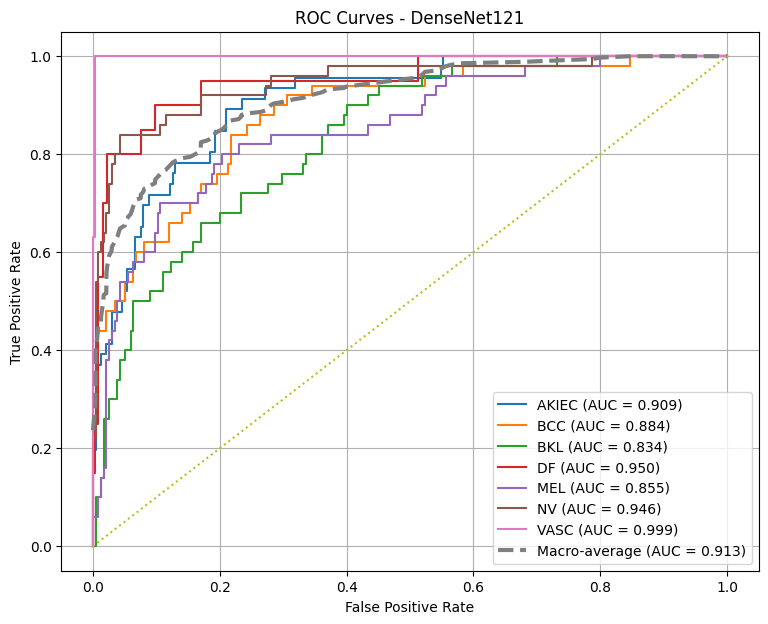

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

fpr_all_dense = []
tpr_all_dense = []

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_onehot_dense[:, i],
        all_probs_dense[:, i]
    )

    roc_auc = auc(fpr, tpr)

    fpr_all_dense.append(fpr)
    tpr_all_dense.append(tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Macro-average ROC curve
all_fpr_dense = np.unique(
    np.concatenate(fpr_all_dense)
)

mean_tpr_dense = np.zeros_like(all_fpr_dense)

for fpr, tpr in zip(fpr_all_dense, tpr_all_dense):
    mean_tpr_dense += np.interp(
        all_fpr_dense,
        fpr,
        tpr
    )

mean_tpr_dense /= len(class_names)

macro_auc_curve_dense = auc(
    all_fpr_dense,
    mean_tpr_dense
)

plt.plot(
    all_fpr_dense,
    mean_tpr_dense,
    linestyle="--",
    linewidth=3,
    label=f"Macro-average (AUC = {macro_auc_curve_dense:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - DenseNet121")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

np.random.seed(42)

y_true = np.array(all_labels_dense)
y_pred = np.array(all_predictions_dense)

n_bootstrap = 2000
n = len(y_true)

accuracy_scores = []
balanced_acc_scores = []
macro_f1_scores = []

for _ in range(n_bootstrap):

    indices = np.random.randint(0, n, n)

    true_sample = y_true[indices]
    pred_sample = y_pred[indices]

    accuracy_scores.append(
        accuracy_score(true_sample, pred_sample)
    )

    balanced_acc_scores.append(
        balanced_accuracy_score(true_sample, pred_sample)
    )

    macro_f1_scores.append(
        f1_score(
            true_sample,
            pred_sample,
            average="macro",
            zero_division=0
        )
    )


def get_ci(scores):
    return (
        np.percentile(scores, 2.5),
        np.percentile(scores, 97.5)
    )


acc_ci = get_ci(accuracy_scores)
bal_ci = get_ci(balanced_acc_scores)
f1_ci = get_ci(macro_f1_scores)

print("DenseNet121 - 95% Confidence Intervals")
print("=" * 50)

print(
    f"Accuracy: {accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {acc_ci[0]:.4f} - {acc_ci[1]:.4f})"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {bal_ci[0]:.4f} - {bal_ci[1]:.4f})"
)

print(
    f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f} "
    f"(95% CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f})"
)

DenseNet121 - 95% Confidence Intervals
Accuracy: 0.6491 (95% CI: 0.5930 - 0.7018)
Balanced Accuracy: 0.6758 (95% CI: 0.6211 - 0.7287)
Macro F1: 0.6770 (95% CI: 0.6199 - 0.7275)


TRANSFORMER


In [ ]:
from torchvision import models
import torch.nn as nn

# Load ImageNet-pretrained Swin Transformer Tiny
swin = models.swin_t(
    weights="IMAGENET1K_V1"
)

# Replace classifier: 1000 ImageNet classes → 7 skin-lesion classes
num_features = swin.head.in_features

swin.head = nn.Linear(
    num_features,
    7
)

# Move to GPU
swin = swin.to(device)

print("Device:", device)
print("Model: Swin Transformer Tiny")
print("Output classes:", swin.head.out_features)

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 116MB/s]


Device: cuda
Model: Swin Transformer Tiny
Output classes: 7


In [ ]:
criterion_swin = nn.CrossEntropyLoss()

optimizer_swin = torch.optim.Adam(
    swin.parameters(),
    lr=0.0001
)

NUM_EPOCHS_SWIN = 10

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Epochs:", NUM_EPOCHS_SWIN)

Loss: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.0001
Epochs: 10


In [ ]:
from tqdm import tqdm
import torch

best_val_acc_swin = 0.0

train_history_swin = []
val_history_swin = []

for epoch in range(NUM_EPOCHS_SWIN):

    # =========================
    # TRAIN
    # =========================
    swin.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS_SWIN} - Swin-Tiny"
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_swin.zero_grad()

        outputs = swin(images)
        loss = criterion_swin(outputs, labels)

        loss.backward()
        optimizer_swin.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # =========================
    # VALIDATION
    # =========================
    swin.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = swin(images)
            loss = criterion_swin(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_history_swin.append((train_loss, train_acc))
    val_history_swin.append((val_loss, val_acc))

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS_SWIN}"
        f"\nTrain Loss: {train_loss:.4f}"
        f" | Train Accuracy: {train_acc:.4f}"
        f"\nVal Loss: {val_loss:.4f}"
        f" | Val Accuracy: {val_acc:.4f}"
    )

    # Save best checkpoint
    if val_acc > best_val_acc_swin:

        best_val_acc_swin = val_acc

        torch.save(
            swin.state_dict(),
            CHECKPOINT_DIR / 'best_swin_tiny_ham10000.pth'
        )

        print("✅ Best Swin-Tiny model saved!")

print("\nSwin Transformer training finished.")
print("Best validation accuracy:", best_val_acc_swin)

Epoch 1/10 - Swin-Tiny: 100%|██████████| 27/27 [00:17<00:00,  1.57it/s]



Epoch 1/10
Train Loss: 1.6017 | Train Accuracy: 0.3762
Val Loss: 1.4243 | Val Accuracy: 0.4508
✅ Best Swin-Tiny model saved!


Epoch 2/10 - Swin-Tiny: 100%|██████████| 27/27 [00:12<00:00,  2.18it/s]



Epoch 2/10
Train Loss: 0.9371 | Train Accuracy: 0.6714
Val Loss: 1.0655 | Val Accuracy: 0.5959
✅ Best Swin-Tiny model saved!


Epoch 3/10 - Swin-Tiny: 100%|██████████| 27/27 [00:12<00:00,  2.15it/s]


...


Epoch 8/10
Train Loss: 0.2253 | Train Accuracy: 0.9143
Val Loss: 1.3451 | Val Accuracy: 0.6166


Epoch 9/10 - Swin-Tiny: 100%|██████████| 27/27 [00:12<00:00,  2.21it/s]



Epoch 9/10
Train Loss: 0.2091 | Train Accuracy: 0.9298
Val Loss: 1.5490 | Val Accuracy: 0.6166


Epoch 10/10 - Swin-Tiny: 100%|██████████| 27/27 [00:12<00:00,  2.23it/s]



Epoch 10/10
Train Loss: 0.1535 | Train Accuracy: 0.9512
Val Loss: 1.3684 | Val Accuracy: 0.6321

Swin Transformer training finished.
Best validation accuracy: 0.6424870466321243


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np
import torch

# Load best Swin checkpoint
swin.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_swin_tiny_ham10000.pth',
        map_location=device
    )
)

swin.eval()

all_predictions_swin = []
all_labels_swin = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = swin(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_swin.extend(
            predictions.cpu().numpy()
        )

        all_labels_swin.extend(
            labels.numpy()
        )

accuracy_swin = accuracy_score(
    all_labels_swin,
    all_predictions_swin
)

precision_swin = precision_score(
    all_labels_swin,
    all_predictions_swin,
    average="macro",
    zero_division=0
)

recall_swin = recall_score(
    all_labels_swin,
    all_predictions_swin,
    average="macro",
    zero_division=0
)

f1_swin = f1_score(
    all_labels_swin,
    all_predictions_swin,
    average="macro",
    zero_division=0
)

print("SWIN-TINY TEST RESULTS")
print("=" * 45)

print(f"Accuracy:        {accuracy_swin:.4f}")
print(f"Macro Precision: {precision_swin:.4f}")
print(f"Macro Recall:    {recall_swin:.4f}")
print(f"Macro F1:        {f1_swin:.4f}")

print("\nDetailed classification report:")

print(
    classification_report(
        all_labels_swin,
        all_predictions_swin,
        target_names=[
            "AKIEC",
            "BCC",
            "BKL",
            "DF",
            "MEL",
            "NV",
            "VASC"
        ],
        zero_division=0
    )
)

SWIN-TINY TEST RESULTS
Accuracy:        0.6737
Macro Precision: 0.7041
Macro Recall:    0.6805
Macro F1:        0.6813

Detailed classification report:
              precision    recall  f1-score   support

       AKIEC       0.59      0.83      0.69        46
         BCC       0.86      0.74      0.80        50
         BKL       0.62      0.42      0.50        50
          DF       0.69      0.45      0.55        20
         MEL       0.54      0.54      0.54        50
          NV       0.68      0.84      0.75        50
        VASC       0.95      0.95      0.95        19

    accuracy                           0.67       285
   macro avg       0.70      0.68      0.68       285
weighted avg       0.68      0.67      0.67       285



In [ ]:
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
import numpy as np

y_true_swin = np.array(all_labels_swin)
y_pred_swin = np.array(all_predictions_swin)

# Balanced Accuracy
balanced_acc_swin = balanced_accuracy_score(
    y_true_swin,
    y_pred_swin
)

print("Balanced Accuracy:",
      round(balanced_acc_swin, 4))

print("Balanced Accuracy (%):",
      round(balanced_acc_swin * 100, 2))


# Confusion Matrix
cm_swin = confusion_matrix(
    y_true_swin,
    y_pred_swin
)

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

print("\nSpecificity by class:")
print("=" * 40)

for i, class_name in enumerate(class_names):

    true_negative = cm_swin.sum() - (
        cm_swin[i, :].sum()
        + cm_swin[:, i].sum()
        - cm_swin[i, i]
    )

    false_positive = (
        cm_swin[:, i].sum() - cm_swin[i, i]
    )

    specificity = true_negative / (
        true_negative + false_positive
    )

    print(
        f"{class_name}: "
        f"{specificity:.4f} "
        f"({specificity * 100:.2f}%)"
    )

Balanced Accuracy: 0.6805
Balanced Accuracy (%): 68.05

Specificity by class:
AKIEC: 0.8912 (89.12%)
BCC: 0.9745 (97.45%)
BKL: 0.9447 (94.47%)
DF: 0.9849 (98.49%)
MEL: 0.9021 (90.21%)
NV: 0.9149 (91.49%)
VASC: 0.9962 (99.62%)


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import torch

# Load best Swin checkpoint
swin.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_swin_tiny_ham10000.pth',
        map_location=device
    )
)

swin.eval()

all_probs_swin = []
all_labels_auc_swin = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = swin(images)

        probs = torch.softmax(outputs, dim=1)

        all_probs_swin.extend(
            probs.cpu().numpy()
        )

        all_labels_auc_swin.extend(
            labels.numpy()
        )

all_probs_swin = np.array(all_probs_swin)
all_labels_auc_swin = np.array(all_labels_auc_swin)

# One-hot encode labels
num_classes = 7

y_true_onehot_swin = np.eye(num_classes)[
    all_labels_auc_swin
]

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

print("Swin-Tiny AUROC by class:")
print("=" * 45)

auc_values_swin = []

for i, class_name in enumerate(class_names):

    auc = roc_auc_score(
        y_true_onehot_swin[:, i],
        all_probs_swin[:, i]
    )

    auc_values_swin.append(auc)

    print(f"{class_name}: {auc:.4f}")

macro_auc_swin = np.mean(auc_values_swin)

print("\nMacro AUROC:",
      round(macro_auc_swin, 4))

print("Macro AUROC (%):",
      round(macro_auc_swin * 100, 2))

Swin-Tiny AUROC by class:
AKIEC: 0.9278
BCC: 0.9598
BKL: 0.8623
DF: 0.9692
MEL: 0.8562
NV: 0.9595
VASC: 0.9988

Macro AUROC: 0.9334
Macro AUROC (%): 93.34


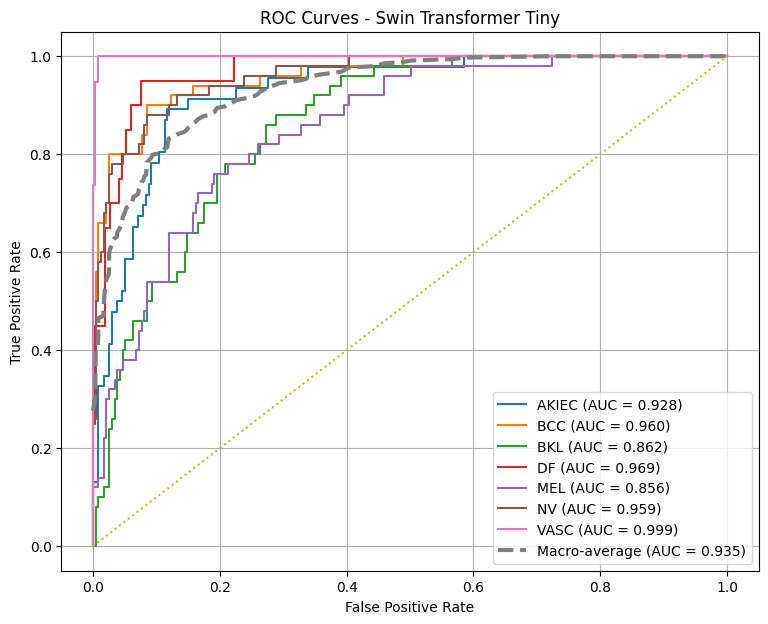

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

fpr_all_swin = []
tpr_all_swin = []

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_onehot_swin[:, i],
        all_probs_swin[:, i]
    )

    roc_auc = auc(fpr, tpr)

    fpr_all_swin.append(fpr)
    tpr_all_swin.append(tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Macro-average ROC
all_fpr_swin = np.unique(
    np.concatenate(fpr_all_swin)
)

mean_tpr_swin = np.zeros_like(all_fpr_swin)

for fpr, tpr in zip(fpr_all_swin, tpr_all_swin):
    mean_tpr_swin += np.interp(
        all_fpr_swin,
        fpr,
        tpr
    )

mean_tpr_swin /= len(class_names)

macro_auc_curve_swin = auc(
    all_fpr_swin,
    mean_tpr_swin
)

plt.plot(
    all_fpr_swin,
    mean_tpr_swin,
    linestyle="--",
    linewidth=3,
    label=f"Macro-average (AUC = {macro_auc_curve_swin:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Swin Transformer Tiny")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

np.random.seed(42)

y_true = np.array(all_labels_swin)
y_pred = np.array(all_predictions_swin)

n_bootstrap = 2000
n = len(y_true)

accuracy_scores = []
balanced_acc_scores = []
macro_f1_scores = []

for _ in range(n_bootstrap):

    indices = np.random.randint(0, n, n)

    true_sample = y_true[indices]
    pred_sample = y_pred[indices]

    accuracy_scores.append(
        accuracy_score(true_sample, pred_sample)
    )

    balanced_acc_scores.append(
        balanced_accuracy_score(
            true_sample,
            pred_sample
        )
    )

    macro_f1_scores.append(
        f1_score(
            true_sample,
            pred_sample,
            average="macro",
            zero_division=0
        )
    )


def get_ci(scores):
    return (
        np.percentile(scores, 2.5),
        np.percentile(scores, 97.5)
    )


acc_ci = get_ci(accuracy_scores)
bal_ci = get_ci(balanced_acc_scores)
f1_ci = get_ci(macro_f1_scores)

print("Swin-Tiny - 95% Confidence Intervals")
print("=" * 50)

print(
    f"Accuracy: {accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {acc_ci[0]:.4f} - {acc_ci[1]:.4f})"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {bal_ci[0]:.4f} - {bal_ci[1]:.4f})"
)

print(
    f"Macro F1: "
    f"{f1_score(y_true, y_pred, average='macro'):.4f} "
    f"(95% CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f})"
)

Swin-Tiny - 95% Confidence Intervals
Accuracy: 0.6737 (95% CI: 0.6175 - 0.7263)
Balanced Accuracy: 0.6805 (95% CI: 0.6248 - 0.7336)
Macro F1: 0.6813 (95% CI: 0.6215 - 0.7304)


In [ ]:
from torchvision import models
import torch.nn as nn

# Load ImageNet-pretrained Vision Transformer
vit = models.vit_b_16(
    weights="IMAGENET1K_V1"
)

# Replace classifier: 1000 ImageNet classes → 7 classes
num_features = vit.heads.head.in_features

vit.heads.head = nn.Linear(
    num_features,
    7
)

# Move to GPU
vit = vit.to(device)

print("Device:", device)
print("Model: Vision Transformer ViT-B/16")
print("Output classes:", vit.heads.head.out_features)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:07<00:00, 48.2MB/s]


Device: cuda
Model: Vision Transformer ViT-B/16
Output classes: 7


In [ ]:
criterion_vit = nn.CrossEntropyLoss()

optimizer_vit = torch.optim.Adam(
    vit.parameters(),
    lr=0.0001
)

NUM_EPOCHS_VIT = 10

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Epochs:", NUM_EPOCHS_VIT)

Loss: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.0001
Epochs: 10


In [ ]:
from tqdm import tqdm
import torch

best_val_acc_vit = 0.0

train_history_vit = []
val_history_vit = []

for epoch in range(NUM_EPOCHS_VIT):

    # =========================
    # TRAIN
    # =========================
    vit.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS_VIT} - ViT-B/16"
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_vit.zero_grad()

        outputs = vit(images)
        loss = criterion_vit(outputs, labels)

        loss.backward()
        optimizer_vit.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # =========================
    # VALIDATION
    # =========================
    vit.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = vit(images)
            loss = criterion_vit(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_history_vit.append((train_loss, train_acc))
    val_history_vit.append((val_loss, val_acc))

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS_VIT}"
        f"\nTrain Loss: {train_loss:.4f}"
        f" | Train Accuracy: {train_acc:.4f}"
        f"\nVal Loss: {val_loss:.4f}"
        f" | Val Accuracy: {val_acc:.4f}"
    )

    # Save best model
    if val_acc > best_val_acc_vit:

        best_val_acc_vit = val_acc

        torch.save(
            vit.state_dict(),
            CHECKPOINT_DIR / 'best_vit_b16_ham10000.pth'
        )

        print("✅ Best ViT-B/16 model saved!")

print("\nViT-B/16 training finished.")
print("Best validation accuracy:", best_val_acc_vit)

Epoch 1/10 - ViT-B/16: 100%|██████████| 27/27 [00:29<00:00,  1.08s/it]



Epoch 1/10
Train Loss: 1.4692 | Train Accuracy: 0.4405
Val Loss: 1.3521 | Val Accuracy: 0.5181
✅ Best ViT-B/16 model saved!


Epoch 2/10 - ViT-B/16: 100%|██████████| 27/27 [00:29<00:00,  1.10s/it]



Epoch 2/10
Train Loss: 0.8783 | Train Accuracy: 0.6774
Val Loss: 1.1083 | Val Accuracy: 0.6010
✅ Best ViT-B/16 model saved!


Epoch 3/10 - ViT-B/16: 100%|██████████| 27/27 [00:31<00:00,  1.16s/it]


...


Epoch 8/10
Train Loss: 0.2580 | Train Accuracy: 0.9071
Val Loss: 1.1841 | Val Accuracy: 0.6321


Epoch 9/10 - ViT-B/16: 100%|██████████| 27/27 [00:30<00:00,  1.15s/it]



Epoch 9/10
Train Loss: 0.2031 | Train Accuracy: 0.9250
Val Loss: 1.0554 | Val Accuracy: 0.6736
✅ Best ViT-B/16 model saved!


Epoch 10/10 - ViT-B/16: 100%|██████████| 27/27 [00:30<00:00,  1.14s/it]



Epoch 10/10
Train Loss: 0.1795 | Train Accuracy: 0.9393
Val Loss: 1.1367 | Val Accuracy: 0.6218

ViT-B/16 training finished.
Best validation accuracy: 0.6735751295336787


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np
import torch

# Load best ViT checkpoint
vit.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_vit_b16_ham10000.pth',
        map_location=device
    )
)

vit.eval()

all_predictions_vit = []
all_labels_vit = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = vit(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_vit.extend(
            predictions.cpu().numpy()
        )

        all_labels_vit.extend(
            labels.numpy()
        )

accuracy_vit = accuracy_score(
    all_labels_vit,
    all_predictions_vit
)

precision_vit = precision_score(
    all_labels_vit,
    all_predictions_vit,
    average="macro",
    zero_division=0
)

recall_vit = recall_score(
    all_labels_vit,
    all_predictions_vit,
    average="macro",
    zero_division=0
)

f1_vit = f1_score(
    all_labels_vit,
    all_predictions_vit,
    average="macro",
    zero_division=0
)

print("VIT-B/16 TEST RESULTS")
print("=" * 45)

print(f"Accuracy:        {accuracy_vit:.4f}")
print(f"Macro Precision: {precision_vit:.4f}")
print(f"Macro Recall:    {recall_vit:.4f}")
print(f"Macro F1:        {f1_vit:.4f}")

print("\nDetailed classification report:")

print(
    classification_report(
        all_labels_vit,
        all_predictions_vit,
        target_names=[
            "AKIEC",
            "BCC",
            "BKL",
            "DF",
            "MEL",
            "NV",
            "VASC"
        ],
        zero_division=0
    )
)

VIT-B/16 TEST RESULTS
Accuracy:        0.6246
Macro Precision: 0.6580
Macro Recall:    0.6388
Macro F1:        0.6421

Detailed classification report:
              precision    recall  f1-score   support

       AKIEC       0.54      0.67      0.60        46
         BCC       0.81      0.60      0.69        50
         BKL       0.48      0.60      0.53        50
          DF       0.60      0.45      0.51        20
         MEL       0.53      0.46      0.49        50
          NV       0.74      0.74      0.74        50
        VASC       0.90      0.95      0.92        19

    accuracy                           0.62       285
   macro avg       0.66      0.64      0.64       285
weighted avg       0.64      0.62      0.63       285



In [ ]:
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
import numpy as np

y_true_vit = np.array(all_labels_vit)
y_pred_vit = np.array(all_predictions_vit)

# Balanced Accuracy
balanced_acc_vit = balanced_accuracy_score(
    y_true_vit,
    y_pred_vit
)

print("Balanced Accuracy:",
      round(balanced_acc_vit, 4))

print("Balanced Accuracy (%):",
      round(balanced_acc_vit * 100, 2))


# Confusion Matrix
cm_vit = confusion_matrix(
    y_true_vit,
    y_pred_vit
)

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

print("\nSpecificity by class:")
print("=" * 40)

for i, class_name in enumerate(class_names):

    true_negative = cm_vit.sum() - (
        cm_vit[i, :].sum()
        + cm_vit[:, i].sum()
        - cm_vit[i, i]
    )

    false_positive = (
        cm_vit[:, i].sum() - cm_vit[i, i]
    )

    specificity = true_negative / (
        true_negative + false_positive
    )

    print(
        f"{class_name}: "
        f"{specificity:.4f} "
        f"({specificity * 100:.2f}%)"
    )

Balanced Accuracy: 0.6388
Balanced Accuracy (%): 63.88

Specificity by class:
AKIEC: 0.8912 (89.12%)
BCC: 0.9702 (97.02%)
BKL: 0.8596 (85.96%)
DF: 0.9774 (97.74%)
MEL: 0.9149 (91.49%)
NV: 0.9447 (94.47%)
VASC: 0.9925 (99.25%)


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import torch

# Load best ViT checkpoint
vit.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / 'best_vit_b16_ham10000.pth',
        map_location=device
    )
)

vit.eval()

all_probs_vit = []
all_labels_auc_vit = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = vit(images)
        probs = torch.softmax(outputs, dim=1)

        all_probs_vit.extend(
            probs.cpu().numpy()
        )

        all_labels_auc_vit.extend(
            labels.numpy()
        )

all_probs_vit = np.array(all_probs_vit)
all_labels_auc_vit = np.array(all_labels_auc_vit)

num_classes = 7

y_true_onehot_vit = np.eye(num_classes)[
    all_labels_auc_vit
]

class_names = [
    "AKIEC",
    "BCC",
    "BKL",
    "DF",
    "MEL",
    "NV",
    "VASC"
]

print("ViT-B/16 AUROC by class:")
print("=" * 45)

auc_values_vit = []

for i, class_name in enumerate(class_names):

    auc = roc_auc_score(
        y_true_onehot_vit[:, i],
        all_probs_vit[:, i]
    )

    auc_values_vit.append(auc)

    print(f"{class_name}: {auc:.4f}")

macro_auc_vit = np.mean(auc_values_vit)

print("\nMacro AUROC:",
      round(macro_auc_vit, 4))

print("Macro AUROC (%):",
      round(macro_auc_vit * 100, 2))

ViT-B/16 AUROC by class:
AKIEC: 0.9130
BCC: 0.9373
BKL: 0.8690
DF: 0.9515
MEL: 0.8538
NV: 0.9514
VASC: 0.9994

Macro AUROC: 0.9251
Macro AUROC (%): 92.51


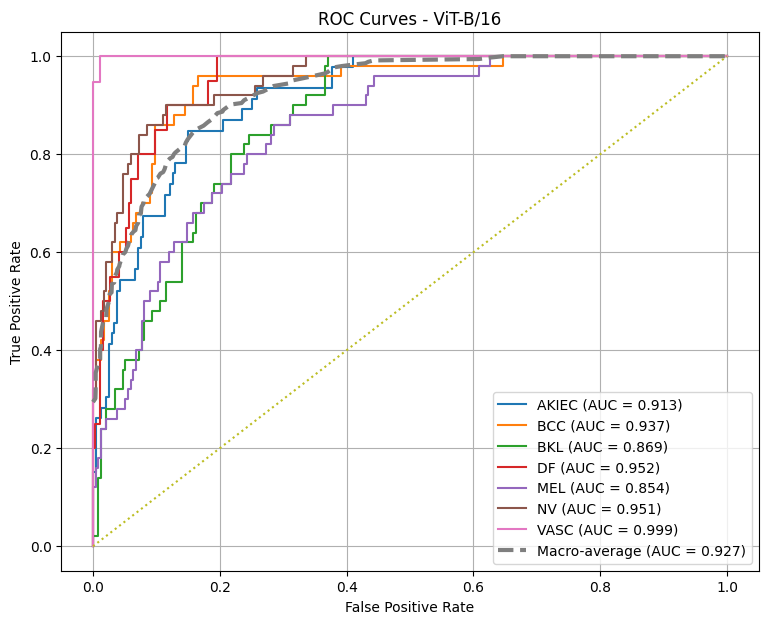

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

fpr_all_vit = []
tpr_all_vit = []

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_onehot_vit[:, i],
        all_probs_vit[:, i]
    )

    roc_auc = auc(fpr, tpr)

    fpr_all_vit.append(fpr)
    tpr_all_vit.append(tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Macro-average ROC
all_fpr_vit = np.unique(
    np.concatenate(fpr_all_vit)
)

mean_tpr_vit = np.zeros_like(all_fpr_vit)

for fpr, tpr in zip(fpr_all_vit, tpr_all_vit):
    mean_tpr_vit += np.interp(
        all_fpr_vit,
        fpr,
        tpr
    )

mean_tpr_vit /= len(class_names)

macro_auc_curve_vit = auc(
    all_fpr_vit,
    mean_tpr_vit
)

plt.plot(
    all_fpr_vit,
    mean_tpr_vit,
    linestyle="--",
    linewidth=3,
    label=f"Macro-average (AUC = {macro_auc_curve_vit:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - ViT-B/16")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

np.random.seed(42)

y_true = np.array(all_labels_vit)
y_pred = np.array(all_predictions_vit)

n_bootstrap = 2000
n = len(y_true)

accuracy_scores = []
balanced_acc_scores = []
macro_f1_scores = []

for _ in range(n_bootstrap):

    indices = np.random.randint(0, n, n)

    true_sample = y_true[indices]
    pred_sample = y_pred[indices]

    accuracy_scores.append(
        accuracy_score(true_sample, pred_sample)
    )

    balanced_acc_scores.append(
        balanced_accuracy_score(
            true_sample,
            pred_sample
        )
    )

    macro_f1_scores.append(
        f1_score(
            true_sample,
            pred_sample,
            average="macro",
            zero_division=0
        )
    )


def get_ci(scores):
    return (
        np.percentile(scores, 2.5),
        np.percentile(scores, 97.5)
    )


acc_ci = get_ci(accuracy_scores)
bal_ci = get_ci(balanced_acc_scores)
f1_ci = get_ci(macro_f1_scores)

print("ViT-B/16 - 95% Confidence Intervals")
print("=" * 50)

print(
    f"Accuracy: {accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {acc_ci[0]:.4f} - {acc_ci[1]:.4f})"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_true, y_pred):.4f} "
    f"(95% CI: {bal_ci[0]:.4f} - {bal_ci[1]:.4f})"
)

print(
    f"Macro F1: "
    f"{f1_score(y_true, y_pred, average='macro'):.4f} "
    f"(95% CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f})"
)

NameError: name 'all_labels_vit' is not defined